# Chapter 19. Reinforcement Learning

Reinforcement learning involves a software _agent_ making observations on it's _environment_ and taking _actions_, recieving _rewards_ from the environment. These rewards can be positive or negative, the goal being to maximize the positive rewards over time.

### Policy Gradients

The algorithm a software agent uses is known as the _policy_ and there are a variety of techniques for optimizing this from random generation brute-force to genetic algorithms that use natural selection to cull bad policies and promote better ones, and finally optimization techniques that calculate the gradients of the rewards with regard to teh policy parameters known as _policy gradient_ (PG) algorithms.

#### Intro to the Gymnasium Library

In order to perform RL we need environments to train our agents! These _can_ be real environments but that gets very expensive and does not scale for most applications, so simulators are necessary. The Open source Gymnasium library (formerly OpenAI Gym) is available for emulating games, 2D and 3D physics simulations, etc.

In [1]:
import gymnasium as gym

env = gym.make("CartPole-v1", render_mode="rgb_array", max_episode_steps=1000)

In [2]:
obs, info = env.reset(seed=42)
obs

array([ 0.0273956 , -0.00611216,  0.03585979,  0.0197368 ], dtype=float32)

In [3]:
info

{}

In [4]:
gym.pprint_registry()

===== classic_control =====
Acrobot-v1             CartPole-v0            CartPole-v1
MountainCar-v0         MountainCarContinuous-v0 Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0     phys2d/CartPole-v1     phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3       BipedalWalkerHardcore-v3 CarRacing-v3
LunarLander-v3         LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1           CliffWalking-v1        CliffWalkingSlippery-v1
FrozenLake-v1          FrozenLake8x8-v1       Taxi-v4
===== tabular =====
tabular/Blackjack-v0   tabular/CliffWalking-v0
===== None =====
Ant-v2                 Ant-v3                 GymV21Environment-v0
GymV26Environment-v0   HalfCheetah-v2         HalfCheetah-v3
Hopper-v2              Hopper-v3              Humanoid-v2
Humanoid-v3            HumanoidStandup-v2     InvertedDoublePendulum-v2
InvertedPendulum-v2    Pusher-v2              Reacher-v2
Swimmer-v2             Swimmer-v3             Walker2d-v2
Walker2d-v3
===== mujoco =====
Ant-v4    

In [5]:
img = env.render()
img.shape  # type: ignore

(400, 600, 3)

In [6]:
env.action_space

Discrete(2)

In [7]:
action = 1  # accelerate right
obs, reward, done, truncated, info = env.step(action)
print(obs)
reward, done, truncated, info

[ 0.02727336  0.18847767  0.03625453 -0.26141977]


(1.0, False, False, {})

In [8]:
def basic_policy(obs):
    """accelerates left if pole leaning right, right if leaning left"""
    angle = obs[2]
    return 0 if angle < 0 else 1


totals = []
for episode in range(500):
    total_rewards = 0
    obs, info = env.reset(seed=episode)
    while True:
        action = basic_policy(obs)
        obs, reward, done, truncated, info = env.step(action)
        total_rewards += reward  # type: ignore
        if done or truncated:
            break
    totals.append(total_rewards)

41.698 8.389445512070509 24.0 63.0


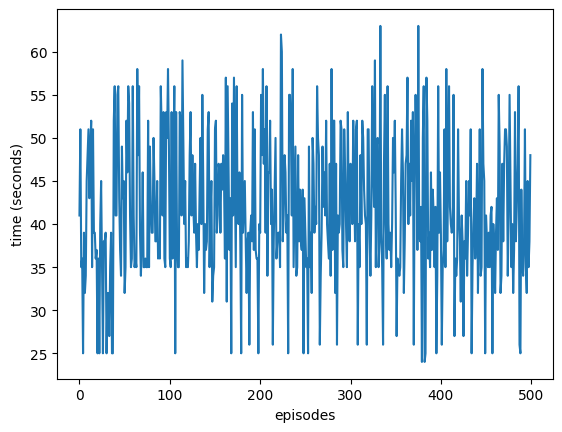

In [9]:
import matplotlib.pyplot as plt
import numpy as np

print(np.mean(totals), np.std(totals), min(totals), max(totals))
fig, ax = plt.subplots()
ax.set_xlabel("episodes")
ax.set_ylabel("time (seconds)")
ax.plot(totals)
plt.show()

As we can see from the plot and the mean, max, etc. this naive approach of simply fully rotating left or right when the pole is leaning is not ideal, the policy is simple and the pole only stays up for a maximum of 63 seconds over 500 episodes. There is also not a huge improvement happening in fact it seems to get worse after a time.

We pick random actions from a distribution of the predicted actions the model wants to make to balance the _exploring_ of new policies that could provide better outcomes, and _exploiting_ known good policies. Another thing to keep in mind is the environment state, wether it is explicit, as is the case with the balancing pole - we always know it's position therefore we know the state regardless of any previous action, or implicit meaning if one aspect was not known to us, we would have to infer it from our previous actions up to that point.

In [10]:
import torch
from torch import nn


class PolicyNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, 5), nn.ReLU(), nn.Linear(5, 1))

    def forward(self, state):
        return self.net(state)

Our 3 layer MLP cake includes a single input layer with 4 input features which match the environment state size of CartPole which is equal to the number of elements in `obs`. We will output 5 features even though the task is binary that way we have a distribution to sample for devloping the policy. This is followed by a typical ReLU to normalize negative values to 0 in order for the model to non-linearize and learn complex patterns. The final output layer has a single output feature because CartPole's action is a binary.

In [11]:
def choose_action(model, obs):
    state = torch.as_tensor(obs)  # convert the observation into a tensor
    logit = model(state)  # get the output from the PolicyNetwork based on the state
    dist = torch.distributions.Bernoulli(
        logits=logit
    )  # Get the distribution of actions from the policy
    action = dist.sample()  # Randomly sample the distribution
    log_prob = dist.log_prob(action)
    return int(action.item()), log_prob

There is the problem of _credit assignment_ how do we know what actions led to the outcome, what do we reward positively or negatively? One way to handle this is implementing a _discount factor_ where the final reward the _return_ is equal to the sum of all the discounted rewards. Using this we can get the model to chain together good actions that lead to a successful final result.

The greater the discount (closer to 1) the more that longer term rewards are counted relative to short term rewards and conversely the lower the discount (closer to 0) long-term rewards count very little relative to short term rewards. Balancing and optimizing this value is based on the environment with typical rewards in the 0.9 to 0.99 range, for CartPole since the actions have relatively short term effects (the pole balancing left to right), a lower discount like 0.8 is fine.

In [12]:
def compute_returns(rewards, discount_factor):
    returns = rewards[:]
    for step in range(len(returns) - 1, 0, -1):
        returns[step - 1] += returns[step] * discount_factor
    return torch.tensor(returns)

In [13]:
compute_returns([10, 0, -50], discount_factor=0.8)

tensor([-22., -40., -50.])

Now we can use a policy gradient that maximizes the return by calculating it as the model plays the game over many episodes. Over time the policy will develop actions that produce a greater return.

In [14]:
def run_episode(model, env, seed=None):
    log_probs, rewards = [], []
    obs, _ = env.reset(seed=seed)
    while True:
        action, log_prob = choose_action(model, obs)
        obs, reward, done, truncated, _ = env.step(action)
        log_probs.append(log_prob)
        rewards.append(reward)

        if done or truncated:
            return log_probs, rewards

In [15]:
def train_reinforce(model, optimizer, env, n_episodes, discount_factor):
    for episode in range(n_episodes):
        seed = torch.randint(0, 2**32, size=()).item()
        log_probs, rewards = run_episode(model, env, seed=seed)
        returns = compute_returns(rewards, discount_factor)
        std_returns = (returns - returns.mean()) / (returns.std() + 1e-7)
        losses = [-logp * rt for logp, rt in zip(log_probs, std_returns)]
        loss = torch.cat(losses).sum()  # compute the total loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        print(f"\rEpisode {episode + 1}, Reward: {sum(rewards):.2f}", end=" ")

This is an implementation of the REINFORCE /montecarlo algorithm.

In [16]:
torch.manual_seed(42)
model = PolicyNetwork()
optimizer = torch.optim.NAdam(model.parameters(), lr=0.06)
train_reinforce(model, optimizer, env, n_episodes=200, discount_factor=0.95)

Episode 200, Reward: 76.00   

## Value-Based Methods
Instead of using the policy gradient to maximize rewards, value based methods try to estimate the value of an action for a given state. It then uses this knowledge to decide how to act through *Markov Decision Processes*. 

## Markov Decision Processes

These are based of Markov Chains wherein you can draw a state dagram with states and actions that have probabilities of moving an agent out of a given state. It follows then that having rewards (positive or negative) associated with actions will lead to a method of determing mathematically for a given discount factor, the optimal policy for each state, meaning the actions to take that maximize reward for each state, which can then be applied to the entire chain to find the optimal policy for the MDP.

### Q-Values
Otherwise known as _Quality Values_, Q-values work by taking the sum of discounted future rewards the agent can expect on average starting from a state if it chooses an action, before it sees teh outcome, assuming a best case scenario after that action is taken.

### Q-Learning
This watches an agent play and uses the information from exploration to estimate the Q-values, once those estimates are close enough the optimal policy chooses the action which maximizes Q-Values. Importantly the agent does not know the transition probabilities or the rewards, it must explore and find them.

This algorithm is called an _off-policy_ algorithm because the policy being trained is not the one used during training, the exploration policy will make the agent better by allowing it to systemically choose the highest Q-Value after the MDP has been sussed out.

### Deep Q-Learning
When MDPs get very large this Q-Learning process does not scale, instead approximations need to be made and using deep neural networks -> deep Q-networks solve this problem.

Implementing a deep Q-network can be done with a neural net that takes a state as input and outputs an approximate Q-Value.

In [17]:
class DQN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 2)
        )

    def forward(self, state):
        return self.net(state)

In [18]:
def choose_dqn_action(model, obs, epsilon=0.0):
    if torch.rand(()) < epsilon:
        return torch.randint(2, size=()).item()
    else:
        state = torch.as_tensor(obs)
        Q_values = model(state)
        return Q_values.argmax().item()

All experiences will get stored in a _replay buffer_ or _memory_ that will then be randomly sampled this way training is not solely influenced by the latest experiences.

In [19]:
def sample_experiences(replay_buffer, batch_size):
    indices = torch.randint(len(replay_buffer), size=[batch_size])
    batch = [replay_buffer[index] for index in indices.tolist()]
    return [to_tensor([exp[index] for exp in batch]) for index in range(6)]


def to_tensor(data):
    array = np.stack(data)
    dtype = torch.float32 if array.dtype == np.float64 else None
    return torch.as_tensor(array, dtype=dtype)

In [20]:
def play_and_record_episode(model, env, replay_buffer, epsilon, seed=None):
    obs, _info = env.reset(seed=seed)
    total_rewards = 0
    model.eval()
    with torch.no_grad():
        while True:
            action = choose_dqn_action(model, obs, epsilon)
            next_obs, reward, done, truncated, _info = env.step(action)
            experience = (
                obs,
                action,
                reward,
                next_obs,
                done,
                truncated,
            )
            replay_buffer.append(experience)
            total_rewards += reward
            if done or truncated:
                return total_rewards
            obs = next_obs

In [21]:
def dqn_training_step(
    model, optimizer, criterion, replay_buffer, batch_size, discount_factor
):
    experiences = sample_experiences(replay_buffer, batch_size)
    state, action, reward, next_state, done, truncated = experiences
    with torch.inference_mode():
        next_Q_value = model(next_state)

    max_next_Q_value, _ = next_Q_value.max(dim=1)
    running = (~(done | truncated)).float()
    target_Q_value = reward + running * discount_factor * max_next_Q_value
    all_Q_values = model(state)
    Q_value = all_Q_values.gather(dim=1, index=action.unsqueeze(1))
    loss = criterion(Q_value, target_Q_value.unsqueeze(1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [22]:
from collections import deque


def train_dqn(
    model,
    env,
    replay_buffer,
    optimizer,
    criterion,
    n_episodes=800,
    warmup=30,
    batch_size=32,
    discount_factor=0.95,
):
    totals = []
    for episode in range(n_episodes):
        epsilon = max(1 - episode / 500, 0.01)
        seed = torch.randint(0, 2**32, size=()).item()
        total_rewards = play_and_record_episode(
            model, env, replay_buffer, epsilon, seed=seed
        )

        print(f"\rEpisode: {episode + 1}, Rewards: {total_rewards}", end=" ")
        totals.append(total_rewards)
        if episode >= warmup:
            dqn_training_step(
                model,
                optimizer,
                criterion,
                replay_buffer,
                batch_size,
                discount_factor,
            )
    return totals

In [23]:
torch.manual_seed(42)
dqn = DQN()
optimizer = torch.optim.NAdam(dqn.parameters(), lr=0.03)
mse = nn.MSELoss()
replay_buffer = deque(maxlen=100_000)
totals = train_dqn(dqn, env, replay_buffer, optimizer, mse)

Episode: 800, Rewards: 1000.0 

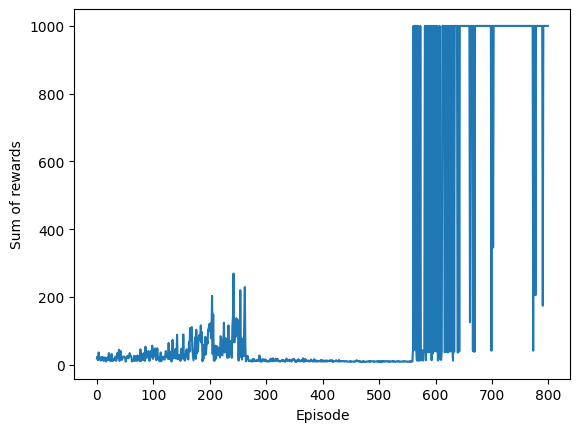

In [24]:
fig, ax = plt.subplots()
ax.set_xlabel("Episode")
ax.set_ylabel("Sum of rewards")
ax.plot(totals)
plt.show()

## Actor-Critic Algorithms
This family of RL algorithms combines the two we have previously covered, Policy Gradient, and Value-based methods. The Policy (actor) uses the values (advantage) of actions from the critic value network to update it's policy, these models are trained simultaneously.

In [25]:
class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(4, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU()
        )
        self.actor_head = nn.Linear(32, 1)  # outputs action logits
        self.critic_head = nn.Linear(32, 1)  # outputs state values

    def forward(self, state):
        features = self.body(state)
        return self.actor_head(features), self.critic_head(features)

In [26]:
def choose_action_and_evaluate(model, obs):
    state = torch.as_tensor(obs)
    logit, state_value = model(state)
    dist = torch.distributions.Bernoulli(logits=logit)
    action = dist.sample()
    log_prob = dist.log_prob(action)
    return int(action.item()), log_prob, state_value

In [27]:
def ac_training_step(
    optimizer, criterion, state_value, target_value, log_prob, critic_weight
):
    td_error = target_value - state_value
    actor_loss = -log_prob * td_error.detach()
    critic_loss = criterion(state_value, target_value)
    loss = actor_loss + critic_loss * critic_weight
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [28]:
def get_target_value(model, next_obs, reward, done, truncated, discount_factor):
    with torch.inference_mode():
        _, _, next_state_value = choose_action_and_evaluate(model, next_obs)

    running = 0.0 if (done or truncated) else 1.0
    target_value = reward + running * discount_factor * next_state_value
    return target_value

In [29]:
def run_episode_and_train(
    model, optimizer, criterion, env, discount_factor, critic_weight, seed=None
):
    obs, _info = env.reset(seed=seed)
    total_rewards = 0
    while True:
        action, log_prob, state_value = choose_action_and_evaluate(model, obs)
        next_obs, reward, done, truncated, _info = env.step(action)
        target_value = get_target_value(
            model, next_obs, reward, done, truncated, discount_factor
        )
        ac_training_step(
            optimizer, criterion, state_value, target_value, log_prob, critic_weight
        )
        total_rewards += reward
        if done or truncated:
            return total_rewards
        obs = next_obs

In [30]:
def train_actor_critic(
    model,
    optimizer,
    criterion,
    env,
    n_episodes=400,
    discount_factor=0.95,
    critic_weight=0.3,
):
    totals = []
    model.train()
    for episode in range(n_episodes):
        seed = torch.randint(0, 2**32, size=()).item()
        total_rewards = run_episode_and_train(
            model,
            optimizer,
            criterion,
            env,
            discount_factor,
            critic_weight,
            seed=seed,
        )
        totals.append(total_rewards)
        print(f"\rEpisode: {episode + 1}, Rewards: {total_rewards}", end=" ")
    return totals

In [31]:
torch.manual_seed(42)
ac_model = ActorCritic()
optimizer = torch.optim.NAdam(ac_model.parameters(), lr=1.1e-3)
criterion = nn.MSELoss()
totals = train_actor_critic(ac_model, optimizer, criterion, env)

Episode: 400, Rewards: 391.0 

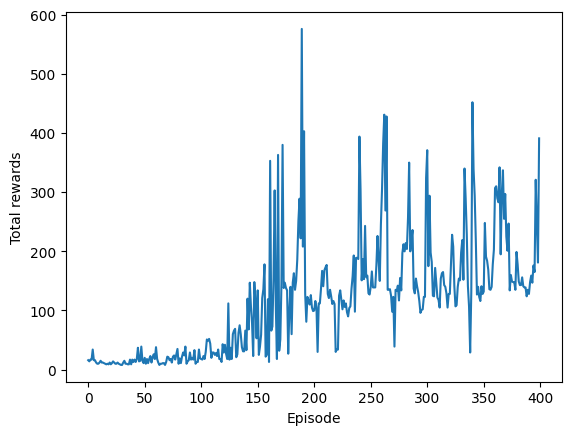

In [32]:
_, ax = plt.subplots()
ax.set_xlabel("Episode")
ax.set_ylabel("Total rewards")
ax.plot(totals)
plt.show()

## Atari Breakout with Stable-Baselines3 PPO

In [33]:
import ale_py

ale = ale_py.ALEInterface()

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


In [34]:
from stable_baselines3.common.env_util import make_atari_env

gym.register_envs(ale_py)
envs = make_atari_env("BreakoutNoFrameskip-v4", n_envs=4)
obs = envs.reset()

objc[12824]: Class SDLApplication is implemented in both /Users/smr/repos/hands-on-ml-notes/.venv/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x111648a68) and /Users/smr/repos/hands-on-ml-notes/.venv/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x13295c890). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[12824]: Class SDLAppDelegate is implemented in both /Users/smr/repos/hands-on-ml-notes/.venv/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x111648ab8) and /Users/smr/repos/hands-on-ml-notes/.venv/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x13295c8e0). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[12824]: Class SDLTranslatorResponder is implemented in both /Users/smr/repos/hands-on-ml-notes/.venv/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x111

In [35]:
from stable_baselines3.common.vec_env import VecFrameStack

envs_stacked = VecFrameStack(envs, n_stack=4)
obs = envs_stacked.reset()

In [36]:
%load_ext tensorboard

In [37]:
tensorboard_logdir = "Part-II-Neural-Networks-And-Deep-Learning/Ch-19-Reinforcement-Learning/breakout_ppo_tensorboard"

%tensorboard --logdir={tensorboard_logdir} --port 6006

In [38]:
from stable_baselines3 import PPO

device = torch.device("mps")
ppo_model = PPO(
    "CnnPolicy",
    envs_stacked,
    device=device,
    learning_rate=2.5e-4,
    batch_size=256,
    n_steps=256,
    n_epochs=44,
    clip_range=0.1,
    vf_coef=0.5,
    ent_coef=0.01,
    gamma=0.99,
    verbose=0,
    tensorboard_log=tensorboard_logdir,
)

In [ ]:
from stable_baselines3.common.callbacks import CheckpointCallback

cb = CheckpointCallback(save_freq=100_000, save_path="my_ppo_breakout.ckpt")
ppo_model.learn(total_timesteps=30_000_000, progress_bar=True, callback=cb)
ppo_model.save("my_ppo_breakout")

Output()

In [ ]:
ppo_model = PPO.load("my_ppo_agent_breakout")
eval_env = make_atari_env("BreakoutNoFrameskip-v4", n_envs=1, seed=42)
eval_stacked = VecFrameStack(eval_env, n_stack=4)
frames = []
obs = eval_stacked.reset()
for _ in range(5000):
    frames.append(eval_stacked.render())
    action, _ = ppo_model.predict(obs, deterministic=True)
    obs, reward, done, info = eval_stacked.step(action)
    if done[0]:
        break
    eval_stacked.close()